## Введение

Для проекта был взять датасет с Росстата из отчета о производстве продукции нескольких зерновых культур по федеральным округам России.

В рамках нашего проекта мы решили визуализировать эти данные, построив круговые и столбчатые диаграммы. 

Для начала импортируем нужные библиотеки:

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Теперь считываем два эксель-файла. Первый - с данными по площадями посевов четырех зерновых культур. Второй - с данными по производству каждого вида зерна. Записывыем их в переменные "area" и "harvest". Дополнительно создаем третью переменную "урожайность", которая считается как отношение урожая к площади

In [ ]:
area = pd.read_excel("ПлощадиПосевов_Га.xlsx", index_col=0) #Считываем файл по площади посевов эксель в переменную
harvest = pd.read_excel("ПроизводствоПосевов_тысцентнеров.xlsx", index_col=0)  #Считываем файл по производству эксель в переменную
reduced_naming = [] #создаем пустой список

for i in area.index:
    clean_name = i[:i.index('федеральный округ')]
    reduced_naming.append(clean_name) #Сокращаем названия округов в таблице до вида "Сибирский"
    
productivity = harvest * 1000 / area #вводим перменную "урожайность", которая отображает урожайность в центнерах с гектара, для этого делим производство на площадь посевов и умножаем на 1000


/opt/anaconda3/lib/python3.13/site-packages/openpyxl/worksheet/header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


Определяем функцию для построения бар-чартов. На ввод подается одна из трех переменных и строится диаграмма. Диаграммы по площадям посевных культур и урожаю построены с логарифмической осью ординат для того, чтобы нагляднее отобразить значения регионов с низкими показателями.

In [10]:
def make_diagram(table, title, ax_y_title):
    '''
    Build a bar chart.

    Keyword arguments:
    table -- table with data to plot (area or harvest or productivity)
    title -- the title of the chart
    ax_y_title -- the label for the y-axis
    '''
    
    ax = table.plot(kind="bar", figsize=(13, 6), width=0.8)  # задаем тип диаграммы, размер и ширину столбиков
    
    for i in ax.containers:
        ax.bar_label(i, fmt="%.1f", fontsize=8) # задаем формат подписей на столбиках, чтобы было видно с точностью до десятых
        
    ax.set_title(title, fontsize=14) # задаем заголовок диаграммы и размер шрифта
    ax.set_ylabel(ax_y_title) # задаем подпись оси Y, которая будет меняться в зависимости от того, что мы передаем в функцию (площадь посевов, сбор урожая или продуктивность)
    ax.set_xlabel("Федеральный округ", fontsize=12) # задаем подпись оси X и размер шрифта
    ax.legend(title="Культура") 
    ax.grid(axis="y", alpha=0.3) # 
    if table is harvest or table is area:
        plt.yscale('log') # если передаем в функцию таблицу по сбору урожая или таблицу по посевным площадям, то меняем шкалу оси Y на логарифмическую, чтобы было видно все культуры
    ax.set_xticklabels(reduced_naming)
    plt.xticks(rotation=30, ha="right")   # задаем наклон подписей на оси x
    plt.tight_layout()
    plt.show()

Визуализируем три диаграммы по площади посевов, сбору урожая и продуктивности с помощью функции make_diagram. В качестве аргументов дополнительно выбираем название таблицы и единицы измерения.

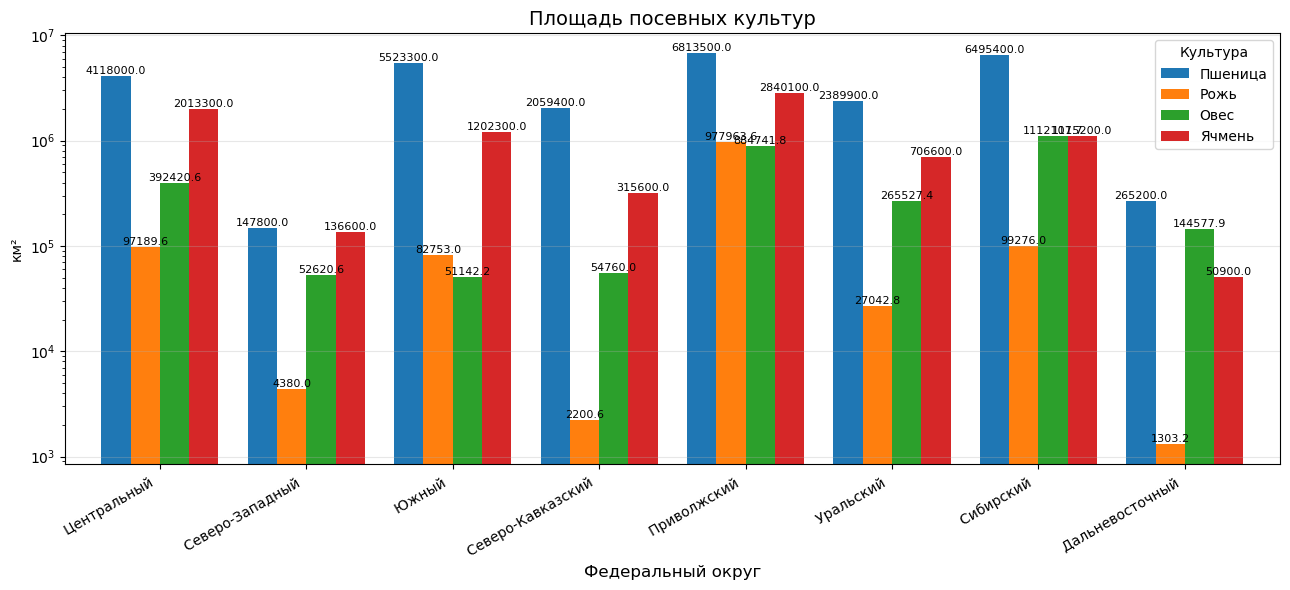

In [8]:
make_diagram(area, 'Площадь посевных культур', 'км²')

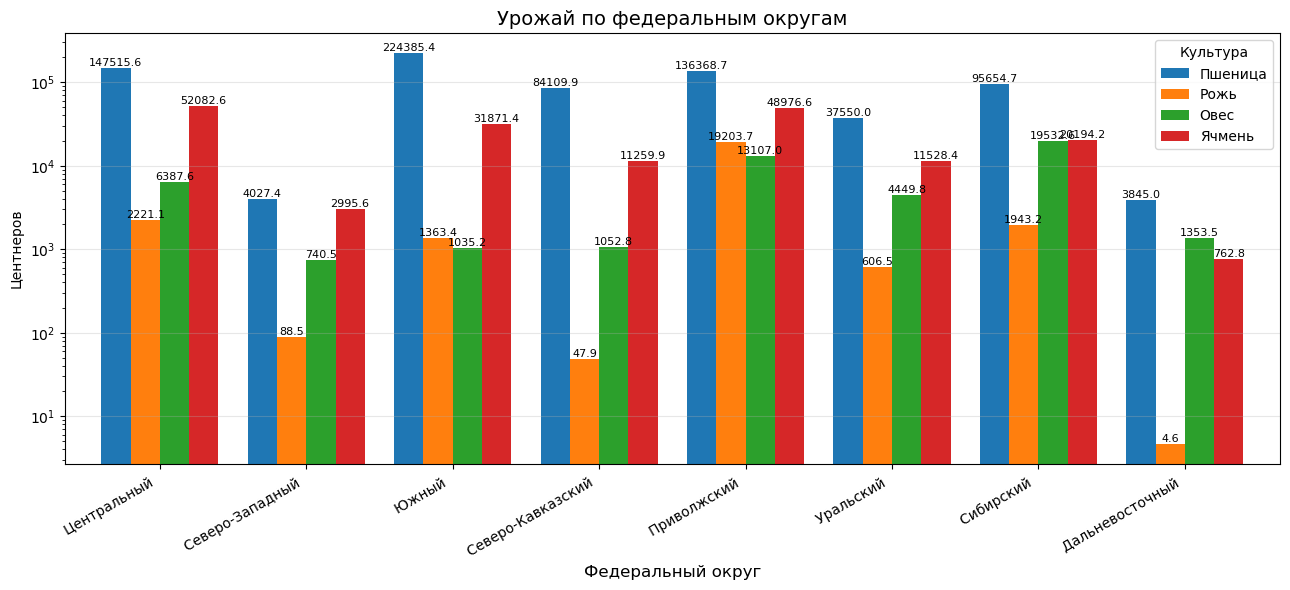

In [9]:
make_diagram(harvest, 'Урожай по федеральным округам', 'Центнеров')

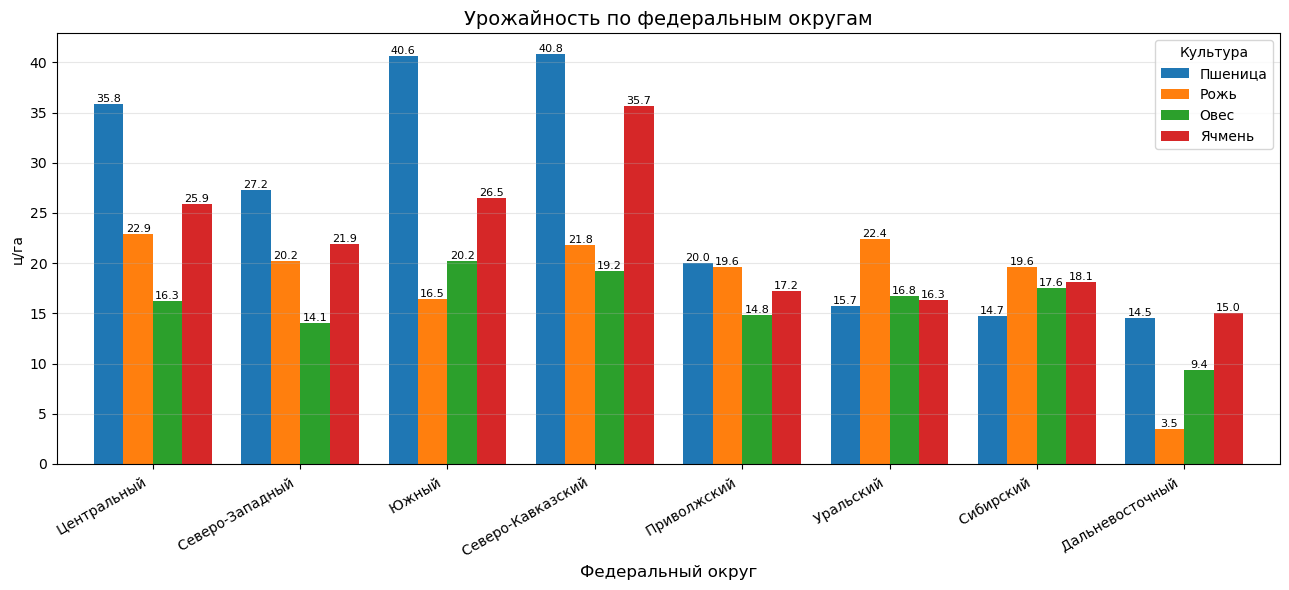

In [60]:
make_diagram(productivity, 'Урожайность по федеральным округам', 'ц/га')

Определяем следующую функцию, которая будет строить диаграмму по выбранной таблице. Для визуализации с помощью функции "subplots" выводим четыре графика: один на каждую культуру. Для лучшей читаемости диаграмм задаем условие, что при значении процента меньше 3, он не отображается на круговой диаграмме. Внутри функции с помощью переменной "каунтер" последовательно берем название каждой культуры из переданной на вход таблицы и для этой культуры строим диаграмму.

In [14]:
def make_piechart(table, title):
    '''Build a pie chart.

    Keyword arguments:
    table -- table with data to plot (area or harvest or productivity)
    title -- the title of the chart

    
    '''
        
    fig, axes = plt.subplots(2, 2, figsize=(12, 12)) # задаем размер фигуры и количество диаграмм на ней (2 на 2)
    counter = 0

    autopct=lambda p: f'{p:.1f}%' if p >= 3 else '' # задаем формат подписей на диаграмме, чтобы было видно с точностью до десятых, но если процент меньше 3%, то не отображать подпись
    
    for i in range(2):
        for j in range(2):
            culture = table[table.columns[counter]] # последовательно передаем в переменную culture каждый столбец таблицы (каждую культуру)
            axes[i,j].pie(culture, labels=reduced_naming, autopct=autopct, textprops={"fontsize": 9}) # задаем параметры для пай-чарта
            axes[i,j].set_title(table.columns[counter], weight='bold', fontsize=15) # последоватльно задаем названием диграммы и параметры шрифта
            counter+=1 #счетким каунтер нужен, чтобы делать изменения последовательно для каждой диаграммы
          
    fig.suptitle(title, fontsize=20)
    plt.tight_layout()
    plt.savefig(str(i))
    

Строим пай-чарты по плошади и урожаю

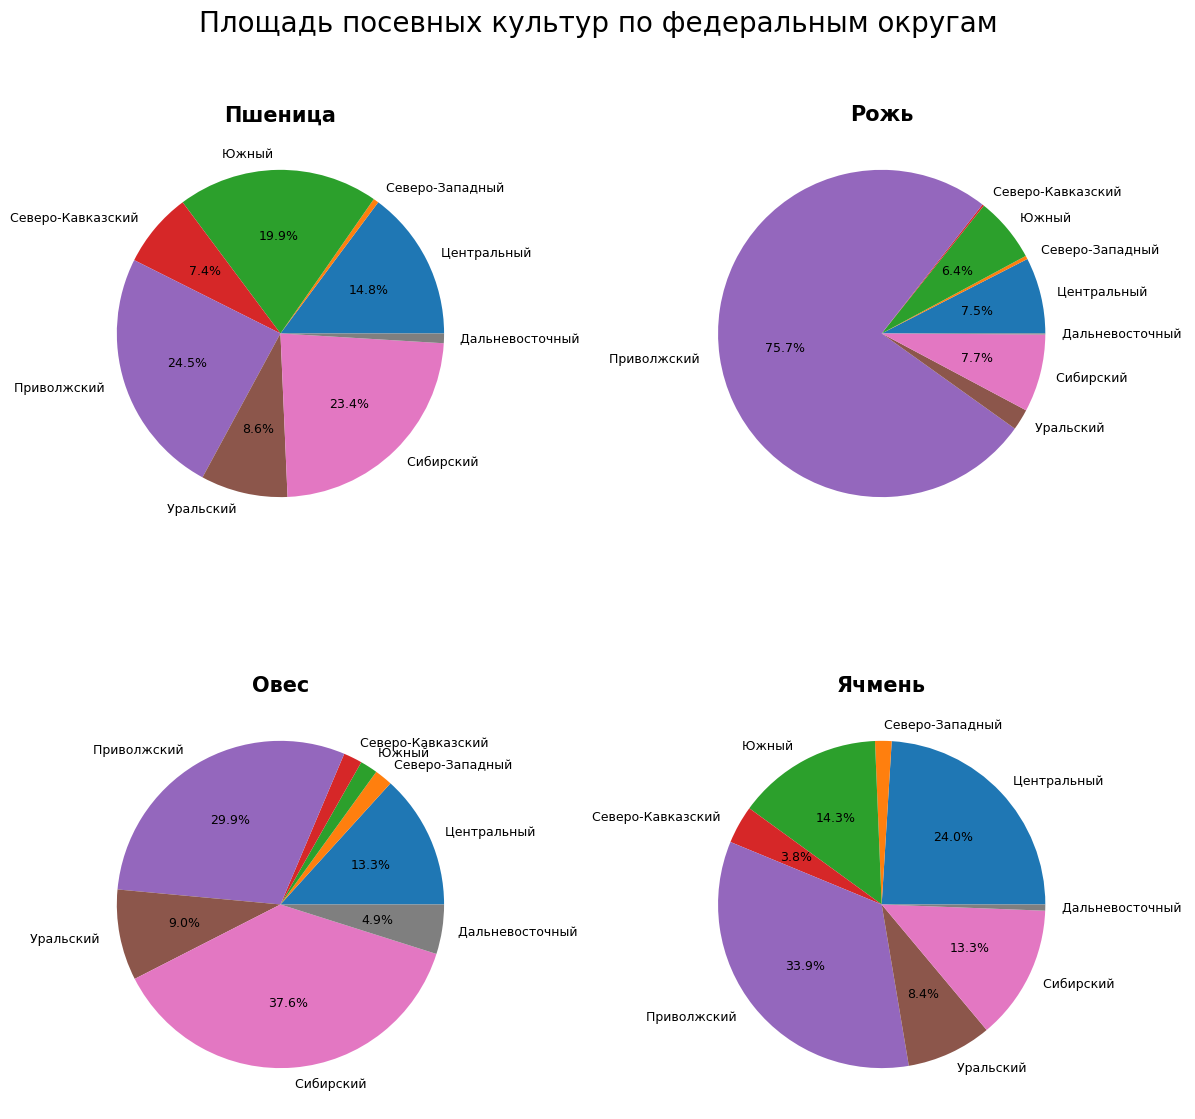

In [16]:
make_piechart(area, 'Площадь посевных культур по федеральным округам')

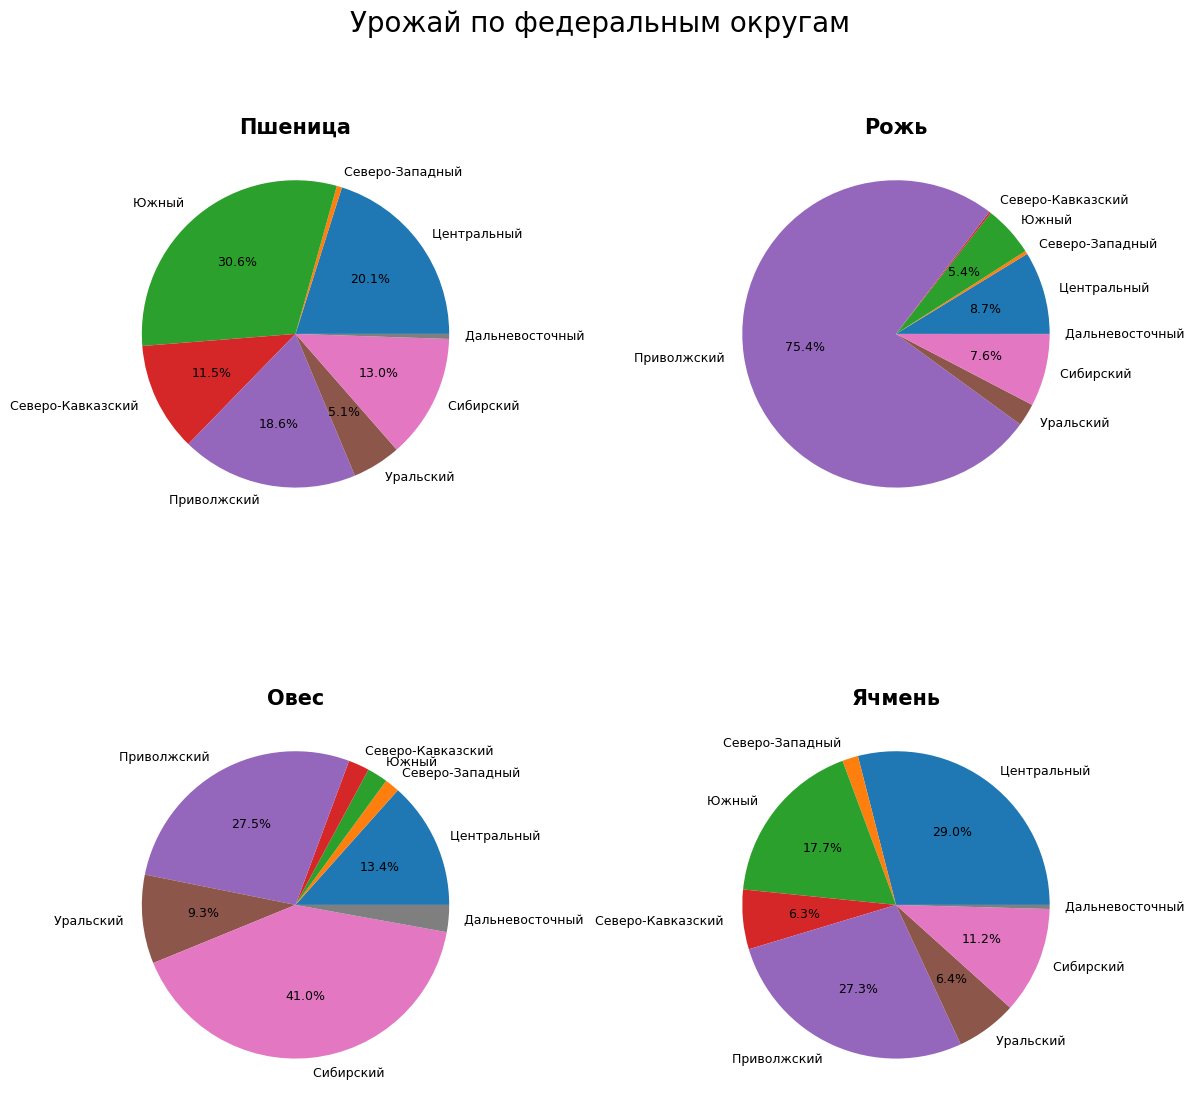

In [19]:
make_piechart(harvest, 'Урожай по федеральным округам')

**Выводы:**

С помощью визуализации данных с Росстата получилось наглядно отобразить дифференциацию сельско-хозяйственных показателей по федеральным округам Российской Федерации. Так, например, из первой из первой столбчатой диаграммы видно, что во всех федеральных округах площадь с/х земель, занятых под пшеницу, превышает площадь, занятую под остальные зерновые культуры. Почти одинакое количество пашни, занятое под пшеницу и ячмень, наблюдается в Северо-западном федеральном округе. Это связано с местными климатическими особенностями: холодные зимы и относительно бедные почвы предраспологает к выращиванию менее прихотливых культур, приемущественно ячменя. 

Соответсвенно, ничего удивительного, что в каждом федеральном округе урожай пшеницы тоже самый большой: под нее заняты самые большие площади

Урожайность с/х культур самая высокая в Центральном, Северо-Кавказском и Южном федеральных округах, что связано с наилучшем климатом для сельского хозяйства. В центральном районе уражайность дополнительно повышается тем, что в этом регионе в агропромышленности используют больше всего удобрений на еденицу площади из-за того, что здесь необходимо удовлетворять самый высокий спрос по всей стране. При этом в СКФО наблюдается аномальная высокая урожайность ячменя, что может быть связано с подходящими относительно богатыми минеральными элементами почвами. 

Самые высокий процент посевных площадей ржи, ячменя и пшеницы находится в ПФО, однако самый высокий урожай пшеницы - в ЮФО, а самый высокий урожай ячменя - в ЦФО



